# 05 · Vending: The "Optimal" Restock Plan Versus the Owner's Rules, and Why the Owner Was Right

**Juan Antonio Sainz Gálvez** · Applied AI & ML, Conestoga College · [Portfolio home](../README.md)

<a href="https://colab.research.google.com/github/antoniosg2025-stack/applied-ai-research-portfolio/blob/main/notebooks/05_vending_owner_rules_restock.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> **Main thesis question.** How can LLM agents learn, from an owner's approvals, rejections and corrections, a **decision profile** grounded in the owner's personality and situation (constraints and strengths: economic, skills, cognitive, family and business), so that they **minimize the gap between the agent's decision and the decision the owner would have made**, across different types of decisions, as the owner evolves, and when other users operate the system on the owner's behalf, **deferring to the owner** whenever that gap is likely to be large?
>
> **Error, in this portfolio, always means:** the agent decided differently from how the owner would have decided.

**This case:** I run four vending machines in Ontario (a car dealership, a hotel, a medical clinic an hour away, and an auto-parts yard). An agent turns the payment terminal's sales data into restock lists. I keep correcting the same things: keep reserve pieces next to the hotel machine, refill chocolates to at least 10 at the clinic and the hotel, buy only by the case, and never make a short trip to the clinic. This notebook asks whether the agent should learn those rules, and measures what each rule costs and saves.


In [1]:
# Visual style used across the portfolio
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import FancyBboxPatch

PALETTE = {"navy": "#1B2A41", "teal": "#0F7C80", "gold": "#E0A526",
           "coral": "#D9534F", "sky": "#5BA4CF", "grey": "#8A94A6", "light": "#F4F6F9"}
POLICY_COLORS = [PALETTE["grey"], PALETTE["sky"], PALETTE["gold"], PALETTE["teal"], PALETTE["coral"]]

mpl.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#D5DAE1", "axes.grid": True, "grid.color": "#E9ECF1", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.titlesize": 14, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 11, "axes.labelcolor": "#3A4556", "xtick.color": "#5A6576", "ytick.color": "#5A6576",
    "legend.frameon": False, "font.family": "DejaVu Sans",
    "axes.prop_cycle": mpl.cycler(color=POLICY_COLORS),
})


def box(ax, xy, w, h, text, color, fontsize=10, text_color="white"):
    """Rounded box for infographics."""
    ax.add_patch(FancyBboxPatch(xy, w, h, boxstyle="round,pad=0.02,rounding_size=0.08", fc=color, ec="none"))
    if text:
        ax.text(xy[0] + w / 2, xy[1] + h / 2, text, ha="center", va="center",
                color=text_color, fontsize=fontsize, fontweight="bold")


def arrow(ax, start, end, color="#8A94A6"):
    ax.annotate("", xy=end, xytext=start,
                arrowprops=dict(arrowstyle="-|>", color=color, lw=2, shrinkA=4, shrinkB=4))


def thesis_card(case, profile, decision, signal):
    """The same infographic opens every notebook: owner profile -> agent decision model -> act or ask."""
    fig, ax = plt.subplots(figsize=(12, 4.6)); ax.set_xlim(0, 12); ax.set_ylim(0, 4.6); ax.axis("off")
    box(ax, (0.1, 0.35), 4.0, 3.5, "", PALETTE["navy"])
    ax.text(2.1, 3.45, "OWNER PROFILE", ha="center", color="white", fontsize=11, fontweight="bold")
    for i, item in enumerate(profile[:5]):
        ax.text(0.3, 2.9 - i * 0.5, "• " + item, color="white", fontsize=9, va="center")
    box(ax, (4.55, 1.55), 3.2, 1.6, "Agent learns how\nthe owner decides:\n" + decision, PALETTE["teal"], fontsize=10.5)
    box(ax, (4.55, 0.35), 3.2, 0.9, "learns from:\n" + signal, PALETTE["sky"], fontsize=9.5)
    box(ax, (8.3, 2.5), 3.5, 1.1, "Likely the same decision\nas the owner  ->  ACT", PALETTE["gold"], fontsize=10.5)
    box(ax, (8.3, 0.75), 3.5, 1.1, "Likely a different decision\n->  ASK THE OWNER", PALETTE["coral"], fontsize=10.5)
    arrow(ax, (4.1, 2.35), (4.5, 2.35)); arrow(ax, (7.8, 2.6), (8.25, 3.0)); arrow(ax, (7.8, 2.1), (8.25, 1.3))
    ax.set_title("Case: " + case, pad=4)
    plt.show()


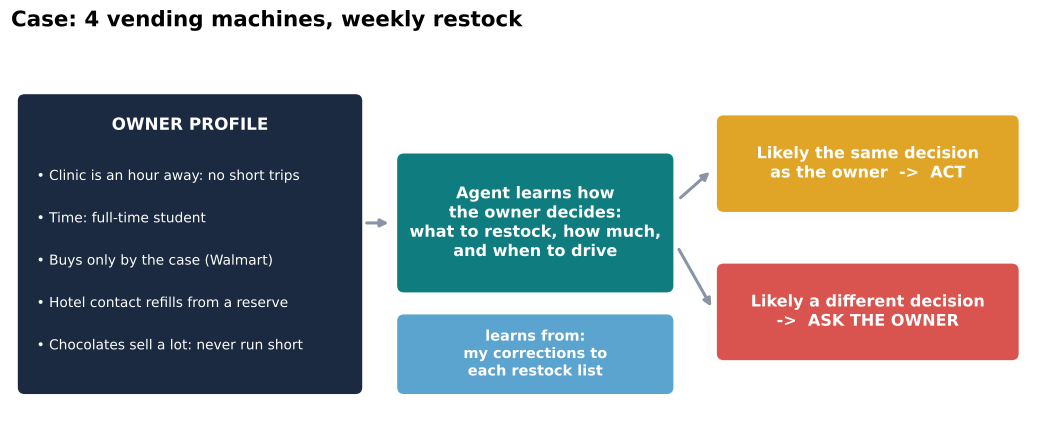

In [2]:
thesis_card("4 vending machines, weekly restock",
            ["Clinic is an hour away: no short trips", "Time: full-time student",
             "Buys only by the case (Walmart)", "Hotel contact refills from a reserve",
             "Chocolates sell a lot: never run short"],
            "what to restock, how much,\nand when to drive",
            "my corrections to\neach restock list")

## 1. Literature

| Research line | Key result | What it gives this case |
|---|---|---|
| Bounded rationality [1] | Real decisions are made under limits of time, information and computation | The owner's limits (classes, a one-hour drive) belong in the decision, not outside it |
| Negative binomial retail demand [2] | Retail demand with unobserved lost sales is better described by a negative binomial than by Poisson | The demand model used below |
| Smart vending inventory and routing [3] | Replenishment points, order-up-to levels and vehicle routes must be decided jointly | The "optimal" planner the owner is compared with |
| Simple heuristics that make us smart [4] | Simple rules of thumb can match or beat complex models when information is limited | The owner's rules may be efficient heuristics, not biases |
| Learning to defer and personalization [5, 6] | Agents should learn when and how to follow a specific human | The agent should learn *these* rules from *this* owner |

**Gap.** Inventory research optimizes a stated cost function. It does not ask what to do when the owner's corrections disagree with the optimum, and whether those corrections carry costs the model does not see.


## 2. The owner's rules (all stated by me while working with the agent)

| Rule | Where | What the agent's plan does without it |
|---|---|---|
| Keep reserve pieces next to the machine (chips and drinks); the hotel contact refills empty coils from it between visits | Hotel | No reserve: empty coils stay empty until the next visit |
| Refill every chocolate coil to at least 10 | Clinic and hotel | Fills to the forecast, often less than 10 |
| Buy only by the case | All | Buys the exact units (not possible at the store) |
| No short trips: go only for a full refill | Clinic | Plans a visit every week |


In [3]:
import numpy as np
import pandas as pd

CATS = [("chips", 4, 8, 1.10, 40), ("chocolate", 6, 10, 1.10, 24), ("drink", 10, 5, 1.40, 24)]  # coils, capacity, margin, case size
MACH = pd.DataFrame([("dealership", 1.30, 16, [1.2, 1.2, 1.2, 1.2, 1.1, 0.5, 0.2]),
                     ("hotel", 1.20, 190, [0.8, 0.8, 0.8, 0.9, 1.2, 1.4, 1.3]),
                     ("clinic", 0.90, 220, [1.3, 1.3, 1.3, 1.3, 1.2, 0.2, 0.0]),
                     ("parts_yard", 0.45, 50, [1.2, 1.2, 1.2, 1.2, 1.2, 0.4, 0.1])],
                    columns=["machine", "base", "km", "dow"]).set_index("machine")
KM_COST, DISP = 0.70, 2.0

rng0 = np.random.default_rng(3)
coils = []
for m, r in MACH.iterrows():
    for cat, n, cap, margin, case in CATS:
        pop = rng0.lognormal(0, 0.45, n); pop /= pop.mean()
        for j in range(n):
            coils.append(dict(machine=m, kind=cat, cap=cap, margin=margin, case=case, mean=r.base * pop[j] * np.mean(r.dow)))
coils = pd.DataFrame(coils)

def nb(rng, mu): return rng.poisson(rng.gamma(DISP, mu / DISP)) if mu > 0 else 0
coils.groupby("machine").agg(coils=("kind", "size"), expected_units_per_day=("mean", "sum"),
                             round_trip_km=("machine", lambda m: MACH.loc[m.iloc[0], "km"])).round(1)

,coils,expected_units_per_day,round_trip_km
machine,,,
clinic,20,17.0,220
dealership,20,24.5,16
hotel,20,24.7,190
parts_yard,20,8.4,50


## 3. Experiment 1: does the agent stop needing the same corrections?

Each week the agent writes a restock list per machine, the owner reviews it and corrects every line that breaks one of his rules, naming the rule. Two agents:

- **No memory of corrections**: the owner corrects the same lines every week (what happened with each new chat or new user).
- **Learns each correction as a rule**: after one correction, the rule is applied by the agent from then on.


In [4]:
RULE_NAMES = ["hotel reserve", "chocolates to 10 (clinic, hotel)", "buy by the case", "clinic: full refill only"]

def plan(week, forecast_col, rules):
    """Restock targets per coil for this week's visits, and the trips."""
    visits = {m: True for m in MACH.index}
    if "clinic: full refill only" in rules:
        visits["clinic"] = week % 2 == 0                         # full refill every two weeks
    target = {}
    for i, c in coils.iterrows():
        if not visits[c.machine]: continue
        days = 14 if (c.machine == "clinic" and "clinic: full refill only" in rules) else 7
        t = min(c.cap, int(np.ceil(c[forecast_col] * days)))
        if "chocolates to 10 (clinic, hotel)" in rules and c.kind == "chocolate" and c.machine in ("clinic", "hotel"):
            t = max(t, 10)
        target[i] = t
    reserve = {"chips": 10, "drink": 12} if "hotel reserve" in rules else {}
    return visits, target, reserve

def violations(visits, target, reserve, rules_learned, week):
    v = 0
    for i, t in target.items():
        c = coils.loc[i]
        if c.kind == "chocolate" and c.machine in ("clinic", "hotel") and t < 10: v += 1
    if not reserve: v += 1
    if "buy by the case" not in rules_learned: v += 1
    if week % 2 == 1 and visits["clinic"]: v += 1               # a short trip to the clinic
    return v

def correction_curve(learns, weeks=12):
    learned, out = set(), []
    for w in range(weeks):
        visits, target, reserve = plan(w, "mean", learned)
        v = violations(visits, target, reserve, learned, w)
        out.append(dict(week=w + 1, corrections=v))
        if learns:
            learned |= set(RULE_NAMES)                           # the owner named every broken rule this week
    return pd.DataFrame(out)

cc = pd.DataFrame({"no memory of corrections": correction_curve(False).set_index("week").corrections,
                   "learns each correction as a rule": correction_curve(True).set_index("week").corrections})
print("Total corrections the owner makes in 12 weeks:"); print(cc.sum())

Total corrections the owner makes in 12 weeks:
no memory of corrections            150
learns each correction as a rule     12
dtype: int64


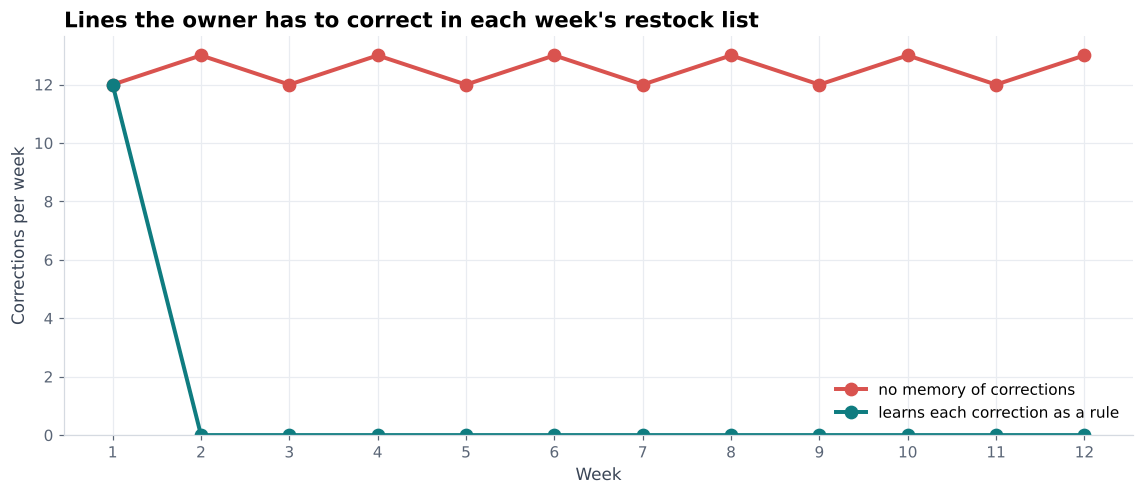

In [5]:
fig, ax = plt.subplots(figsize=(10.5, 4.6))
ax.plot(cc.index, cc["no memory of corrections"], "-o", color=PALETTE["coral"], lw=2.6, ms=8, label="no memory of corrections")
ax.plot(cc.index, cc["learns each correction as a rule"], "-o", color=PALETTE["teal"], lw=2.6, ms=8, label="learns each correction as a rule")
ax.set_xticks(cc.index); ax.set_ylim(bottom=0)
ax.set_title("Lines the owner has to correct in each week's restock list")
ax.set_xlabel("Week"); ax.set_ylabel("Corrections per week"); ax.legend()
plt.tight_layout(); plt.show()

## 4. Experiment 2: what does each of the owner's rules cost and save?

12 weeks of demand are simulated with stockouts. The **optimal plan** fills each coil to its forecast demand until the next visit and visits every machine every week. Then each owner rule is added alone, and finally all of them together. Outcome: margin lost to empty coils, travel cost, and margin kept after travel (all per week).


In [6]:
def simulate(forecast_col, rules, weeks=12, seed=11):
    rng = np.random.default_rng(seed)
    stock = coils.cap.to_numpy().copy(); lost = sold_m = travel = 0.0
    reserve_left = {}
    for w in range(weeks):
        visits, target, reserve = plan(w, forecast_col, rules)
        for m, go in visits.items():
            if go: travel += MACH.loc[m, "km"] * KM_COST
        for i, t in target.items(): stock[i] = max(stock[i], t)
        reserve_left = dict(reserve)
        for d in range(7):
            for i, c in coils.iterrows():
                dem = nb(rng, c["mean"] / np.mean(MACH.loc[c.machine, "dow"]) * MACH.loc[c.machine, "dow"][d])
                s = min(dem, stock[i]); stock[i] -= s; sold_m += s * c.margin; lost += (dem - s) * c.margin
                if stock[i] == 0 and c.machine == "hotel" and reserve_left.get(c.kind, 0) > 0:
                    add = min(c.cap, reserve_left[c.kind]); stock[i] += add; reserve_left[c.kind] -= add
    return dict(margin_lost=lost / weeks, travel_cost=travel / weeks, margin_after_travel=(sold_m - travel) / weeks)

ALL = set(RULE_NAMES)
cases = [("optimal plan", set())] + [("+ " + r, {r}) for r in RULE_NAMES if r != "buy by the case"] + [("all owner's rules", ALL)]
money = pd.DataFrame({name: simulate("mean", r) for name, r in cases}).T.round(0)
money.columns = ["margin lost to empty coils ($/week)", "travel cost ($/week)", "margin after travel ($/week)"]
money

,margin lost to empty coils ($/week),travel cost ($/week),margin after travel ($/week)
optimal plan,221.0,333.0,83.0
+ hotel reserve,199.0,333.0,104.0
"+ chocolates to 10 (clinic, hotel)",214.0,333.0,90.0
+ clinic: full refill only,251.0,256.0,130.0
all owner's rules,226.0,256.0,155.0


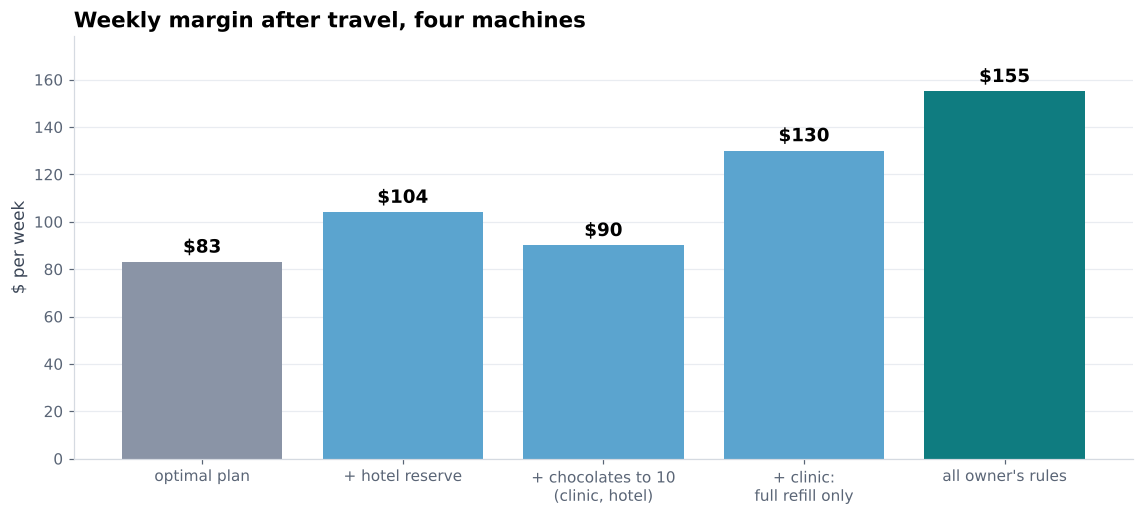

In [7]:
fig, ax = plt.subplots(figsize=(10.5, 4.8))
cols = [PALETTE["grey"], PALETTE["sky"], PALETTE["sky"], PALETTE["sky"], PALETTE["teal"]]
vals = money["margin after travel ($/week)"]
bars = ax.bar([n.replace(" (clinic, hotel)", "\n(clinic, hotel)").replace(": ", ":\n") for n in money.index], vals, color=cols)
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + 4, f"${v:,.0f}", ha="center", fontsize=12, fontweight="bold")
ax.set_ylim(0, vals.max() * 1.15); ax.grid(axis="x", visible=False)
ax.set_title("Weekly margin after travel, four machines")
ax.set_ylabel("$ per week")
plt.tight_layout(); plt.show()

## 5. Findings

> **Key finding 1.** Without memory, the owner corrects the same lines every week (150 corrections in 12 weeks: every chocolate coil, the reserve, the cases and the short trip); an agent that turns each correction into a rule needs them **once** (12, all in the first week). This is the re-specification cost from notebook 01, measured on a real routine.
>
> **Key finding 2.** The "optimal" plan is optimal for a cost function that leaves out the owner's situation. The rule "no short trips to the clinic" **loses a little more margin** to empty coils (about \$30 a week) but saves about \$77 a week in driving, the largest single gain. With all of the owner's rules, margin after travel goes from about \$83 to \$155 a week. The owner was trading lost sales for an hour of road each way, a trade the planner could not see because his time and distance were not in its objective.
>
> **Key finding 3.** The hotel reserve recovers about \$21 a week of sales between visits at almost no cost, and the chocolate minimum adds about \$7, because most of those coils already fill to capacity. An agent that learns the owner's rules **and** measures what each one costs and saves can tell the owner which rules carry the result, instead of obeying all of them blindly or overriding them.

**Limitations:** synthetic demand calibrated to my coil layout, illustrative distances, and case sizes that only affect the purchase list (extra units go to home stock).

## 6. Thesis questions

1. Can an agent infer *why* an owner's rule works (here, the owner's travel time) and propose to drop it when the reason no longer holds?
2. When the owner's situation changes (for example, moving to Alberta and not visiting the clinic at all), which rules should transfer to a new set of machines?
3. How should the agent present a disagreement with the owner (with evidence, in money) without overriding him?

## References

1. Simon, H. A. (1955). *A behavioral model of rational choice.* Quarterly Journal of Economics, 69(1), 99–118.
2. Agrawal, N., & Smith, S. A. (1996). *Estimating negative binomial demand for retail inventory management with unobservable lost sales.* Naval Research Logistics, 43(6), 839–861.
3. Park, Y.-B., & Yoo, J.-S. (2012). *A heuristic for the inventory management of smart vending machine systems.* Journal of Industrial Engineering and Management, 5(2), 354–363.
4. Gigerenzer, G., Todd, P. M., & the ABC Research Group (1999). *Simple Heuristics That Make Us Smart.* Oxford University Press.
5. Mozannar, H., & Sontag, D. (2020). *Consistent Estimators for Learning to Defer to an Expert.* ICML 2020.
6. Salemi, A., et al. (2024). *LaMP: When Large Language Models Meet Personalization.* ACL 2024.
